<a href="https://colab.research.google.com/github/Avinash2567/MACHINE-LEARNING-ALGORITHM-IMPLEMENTATIONS/blob/main/09-support-vector-machine/02-nonlinear-support-vector-machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
data = pd.read_csv(
    "/content/heart_failure_clinical_records_dataset.csv"
)

data.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:
data.shape

(299, 13)

In [4]:
data.columns

Index(['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time',
       'DEATH_EVENT'],
      dtype='object')

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [6]:
data.isnull().sum()

,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0


In [7]:
print("Number of duplicate rows:", data.duplicated().sum())

Number of duplicate rows: 0


In [8]:
data = data.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", data.shape)

Dataset shape after removing duplicates: (299, 13)


In [9]:
data.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


In [10]:
X = data[["age", "ejection_fraction"]]
y = data["DEATH_EVENT"]

print("Input features:")
display(X.head())

print("\nTarget values:")
print(y.value_counts())

Input features:


,age,ejection_fraction
0,75.0,20
1,55.0,38
2,65.0,20
3,50.0,20
4,65.0,20



Target values:
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (239, 2)
Testing data shape: (60, 2)


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

model.fit(X_train_scaled, y_train)

print("Non-Linear SVM model trained successfully!")

Non-Linear SVM model trained successfully!


In [14]:
y_pred = model.predict(X_test_scaled)

print("Actual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)

Actual values:
[0 0 0 0 0 0 0 1 0 0 1 1 1 0 1 1 1 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 1 1
 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 1 0 0]

Predicted values:
[0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0]


In [15]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 71.67 %


Confusion Matrix:
[[37  4]
 [13  6]]


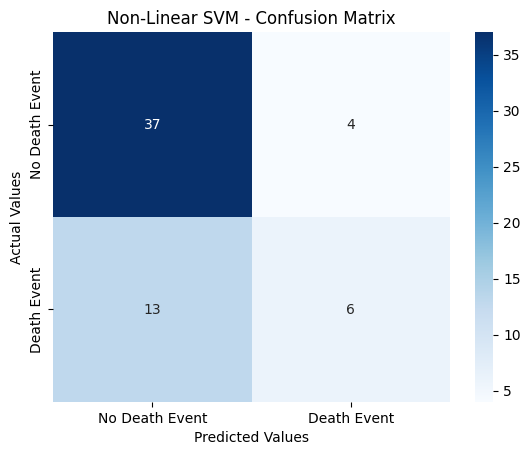

In [16]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Death Event", "Death Event"],
    yticklabels=["No Death Event", "Death Event"]
)

plt.title("Non-Linear SVM - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

In [17]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Death Event", "Death Event"],
        zero_division=0
    )
)

                precision    recall  f1-score   support

No Death Event       0.74      0.90      0.81        41
   Death Event       0.60      0.32      0.41        19

      accuracy                           0.72        60
     macro avg       0.67      0.61      0.61        60
  weighted avg       0.70      0.72      0.69        60



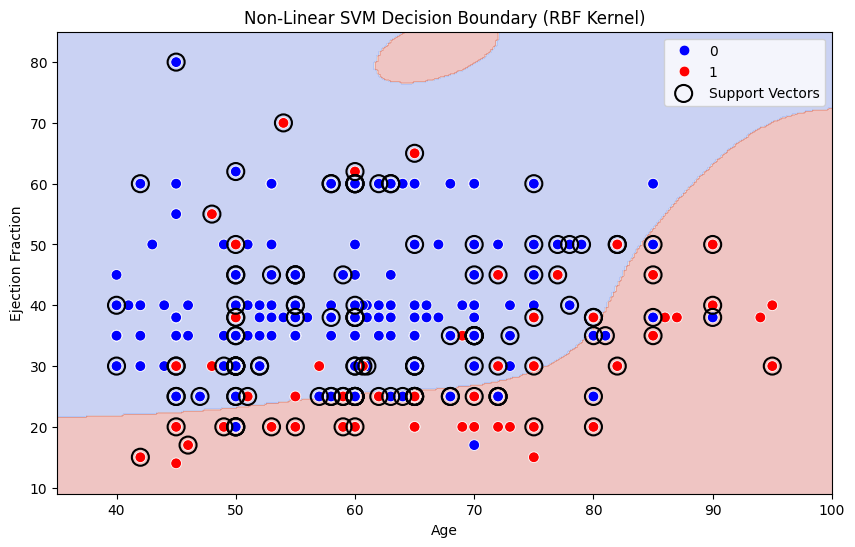

In [18]:
# Create a mesh grid in the original feature scale
x_min, x_max = X["age"].min() - 5, X["age"].max() + 5
y_min, y_max = (
    X["ejection_fraction"].min() - 5,
    X["ejection_fraction"].max() + 5
)

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Convert grid points into a DataFrame with matching columns
grid = pd.DataFrame({
    "age": xx.ravel(),
    "ejection_fraction": yy.ravel()
})

# Scale the grid and predict classes
grid_scaled = scaler.transform(grid)
Z = model.predict(grid_scaled)
Z = Z.reshape(xx.shape)

# Plot decision regions and data points
plt.figure(figsize=(10, 6))

plt.contourf(
    xx, yy, Z,
    alpha=0.3,
    cmap="coolwarm"
)

sns.scatterplot(
    data=data,
    x="age",
    y="ejection_fraction",
    hue="DEATH_EVENT",
    palette={0: "blue", 1: "red"},
    s=60
)

# Show support vectors in original feature units
support_vectors = scaler.inverse_transform(model.support_vectors_)

plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=150,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support Vectors"
)

plt.title("Non-Linear SVM Decision Boundary (RBF Kernel)")
plt.xlabel("Age")
plt.ylabel("Ejection Fraction")
plt.legend()
plt.show()